# Ranking check: does the twin rank circuits like the real circuit does?

The search will score genomes with the classical twin instead of training a circuit, which takes milliseconds instead of seconds. That is only safe if the twin puts genomes in the same order as short-trained circuits do. This notebook checks it on the L/14 input pool.

1. **Genomes:** 8 of the 144 pool columns, an encoding gate and a rotation gate, no entanglers. Half of the masks lean on the strongest columns and half are random, so the genomes span a wide range of quality.
2. **Circuit fitness:** the same short training as the earlier searches (2,000 fitness frames, 6 epochs, batch 100, lr 0.1), frame AUC on the inner fitness frames. Each genome is trained with 3 seeds.
3. **Twin fitness:** logistic regression on the twin features of the same 8 columns, scored on the same inner frames.
4. **Pass rule:** Spearman between twin fitness and mean circuit fitness of at least 0.6. The seed-to-seed Spearman of the circuits is printed next to it, as the best agreement noise allows.

In [1]:
backbone = "l14"
n_genomes = 60
seeds = [0, 1, 2]
strong_top = 24             # masks of the first half draw some columns from the 24 strongest
encodings = ["RX", "RY", "H+RZ"]
rotations = ["RY", "RX+RY", "Rot"]
fit_per_class = 1000
fit_lr = 0.1
fit_epochs = 6
fit_batch = 100
twin_c = [0.01, 0.1, 1.0]
pass_spearman = 0.6
n_jobs = 0                  # 0 = one job per CPU core
out_dir = "/kaggle/working/ranking_check"
seed = 0

In [2]:
!pip install -q pennylane==0.45.1

In [3]:
import os
import glob
import json
import time
import multiprocessing as mp

import numpy as np
import pandas as pd
import torch
import pennylane as qml
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

torch.set_num_threads(1)
os.makedirs(out_dir, exist_ok=True)
if n_jobs == 0:
    n_jobs = os.cpu_count()
print("pennylane", qml.__version__, "| torch", torch.__version__, "| jobs", n_jobs)

pennylane 0.45.1 | torch 2.11.0+cpu | jobs 4


## Load the pool

In [4]:
def find(pattern):
    for depth in range(8):
        hits = glob.glob("/kaggle/input/" + "*/" * depth + pattern)
        if len(hits) > 0:
            return hits[0]
    raise FileNotFoundError(pattern)


pool = np.load(find(backbone + "_ffpp_train_pool.npy")).astype(np.float64)
rows = pd.read_csv(find("ffpp_train_rows.csv"), dtype={"video_id": str})
is_inner = np.load(find("ffpp_train_is_inner.npy")).astype(bool)
strength = pd.read_csv(find(backbone + "_column_strength.csv"))
columns = json.load(open(find("columns.json")))
assert len(pool) == len(rows) == len(is_inner)
y = rows["label"].to_numpy()
n_cols = pool.shape[1]
strong = strength.sort_values("strength_search_train", ascending=False).index[:strong_top].tolist()
print(backbone, "pool", pool.shape, "| strongest columns:", [columns[j] for j in strong[:8]])

l14 pool (46076, 144) | strongest columns: ['pls0', 'pca1', 'pls1', 'pca5', 'pca8', 'pca2', 'pls4', 'pca11']


## Fitness frames

Same code and seed as the earlier searches: 1,000 real and 1,000 fake search-train frames, at most 2 per real video and 1 per fake video.

In [5]:
st_index = np.where(~is_inner)[0]
st_rows = rows.iloc[st_index].copy()
st_rows["row"] = st_index
rng = np.random.default_rng(0)
real_pick = st_rows[st_rows["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
fake_pick = st_rows[st_rows["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
fit_index = np.concatenate([rng.choice(real_pick, fit_per_class, replace=False),
                            rng.choice(fake_pick, fit_per_class, replace=False)])
inner_index = np.where(is_inner)[0]
print("fitness frames", len(fit_index), "| inner frames", len(inner_index))

fitness frames 2000 | inner frames 6912


## Genomes

The first half of the masks take between 2 and 8 columns from the strongest 24 and fill the rest at random; the second half are fully random.

In [6]:
def random_mask(rng, n_strong):
    picked = rng.choice(strong, n_strong, replace=False).tolist()
    rest = [j for j in range(n_cols) if j not in picked]
    picked += rng.choice(rest, 8 - n_strong, replace=False).tolist()
    return sorted(int(j) for j in picked)


rng = np.random.default_rng(seed)
genomes = []
keys = set()
while len(genomes) < n_genomes:
    n_strong = int(rng.integers(2, 9)) if len(genomes) < n_genomes // 2 else 0
    g = {"mask": random_mask(rng, n_strong), "encoding": encodings[rng.integers(len(encodings))],
         "rotation": rotations[rng.integers(len(rotations))]}
    key = ".".join(str(j) for j in g["mask"]) + "|" + g["encoding"] + "|" + g["rotation"]
    if key not in keys:
        keys.add(key)
        g["key"] = key
        genomes.append(g)
print(len(genomes), "genomes, e.g.", genomes[0]["key"])

60 genomes, e.g. 1.2.96.128.130.132.134.139|H+RZ|RX+RY


## The twin

With no entanglers, each qubit is measured on its own, so the readout is a weighted sum of one function per input. For one qubit that function is a fixed mix of sin x and cos x, set by the encoding and the rotation:

- RY encoding: the state's Bloch vector is (sin x, 0, cos x), and any rotation can reach both terms, so the twin feature is [sin x, cos x].
- RX or H+RZ encoding with only RY rotations: the RY rotation can only read the part of the Bloch vector that already lies in its plane, which leaves cos x alone.
- RX or H+RZ encoding with RX+RY or Rot rotations: both terms.

The twin is logistic regression on those features, trained on the fitness frames and scored on the inner frames.

In [7]:
def twin_features(x, genome):
    if genome["encoding"] != "RY" and genome["rotation"] == "RY":
        return np.cos(x)
    return np.hstack([np.sin(x), np.cos(x)])


def twin_fitness(genome, c):
    x = pool[:, genome["mask"]]
    model = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000))
    model.fit(twin_features(x[fit_index], genome), y[fit_index])
    return roc_auc_score(y[inner_index], model.predict_proba(twin_features(x[inner_index], genome))[:, 1])


twin_scores = {c: [twin_fitness(g, c) for g in genomes] for c in twin_c}
print("twin fitness range at C = 1: %.3f to %.3f" % (min(twin_scores[1.0]), max(twin_scores[1.0])))

twin fitness range at C = 1: 0.524 to 0.853


## The circuit

Same circuit and training as the earlier searches, with one layer and no entangler: encoding, one rotation layer, ⟨Z⟩ on all 8 qubits, then a weighted sum plus bias.

In [8]:
n_qubits = 8
angles_per_rotation = {"RY": 1, "RX+RY": 2, "Rot": 3}


def make_qnode(genome):
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, w):
        for i in range(n_qubits):
            if genome["encoding"] == "RX":
                qml.RX(x[:, i], wires=i)
            elif genome["encoding"] == "RY":
                qml.RY(x[:, i], wires=i)
            else:
                qml.Hadamard(wires=i)
                qml.RZ(x[:, i], wires=i)
        for i in range(n_qubits):
            if genome["rotation"] == "RY":
                qml.RY(w[i, 0], wires=i)
            elif genome["rotation"] == "RX+RY":
                qml.RX(w[i, 0], wires=i)
                qml.RY(w[i, 1], wires=i)
            else:
                qml.Rot(w[i, 0], w[i, 1], w[i, 2], wires=i)
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    return circuit


class VQC(torch.nn.Module):
    def __init__(self, genome):
        super().__init__()
        self.circuit = make_qnode(genome)
        k = angles_per_rotation[genome["rotation"]]
        self.w = torch.nn.Parameter(0.1 * torch.randn(n_qubits, k, dtype=torch.float64))
        self.readout = torch.nn.Linear(n_qubits, 1, dtype=torch.float64)
        torch.nn.init.normal_(self.readout.weight, std=0.1)
        torch.nn.init.zeros_(self.readout.bias)

    def forward(self, x):
        z = torch.stack(self.circuit(x, self.w), dim=-1).to(torch.float64)
        return self.readout(z).squeeze(-1)


def circuit_fitness(item):
    torch.set_num_threads(1)
    i, s = item
    genome = genomes[i]
    start = time.time()
    torch.manual_seed(s)
    model = VQC(genome)
    opt = torch.optim.Adam(model.parameters(), lr=fit_lr)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    xt = torch.tensor(pool[fit_index][:, genome["mask"]], dtype=torch.float64)
    yt = torch.tensor(y[fit_index], dtype=torch.float64)
    gen = torch.Generator().manual_seed(s)
    for epoch in range(fit_epochs):
        order = torch.randperm(len(xt), generator=gen)
        for start_b in range(0, len(xt), fit_batch):
            idx = order[start_b:start_b + fit_batch]
            opt.zero_grad()
            loss_fn(model(xt[idx]), yt[idx]).backward()
            opt.step()
    with torch.no_grad():
        xi = torch.tensor(pool[inner_index][:, genome["mask"]], dtype=torch.float64)
        prob = torch.sigmoid(model(xi)).numpy()
    return {"genome": i, "seed": s, "circuit_auc": roc_auc_score(y[inner_index], prob), "seconds": time.time() - start}


items = [(i, s) for i in range(len(genomes)) for s in seeds]
start_all = time.time()
with mp.get_context("fork").Pool(n_jobs) as workers:
    runs = pd.DataFrame(workers.map(circuit_fitness, items))
print("%d circuits trained in %.1f min, %.1f s each" % (len(runs), (time.time() - start_all) / 60, runs["seconds"].mean()))

180 circuits trained in 4.4 min, 5.5 s each


## Agreement

In [9]:
table = pd.DataFrame([{"key": g["key"], "n_strong": sum(j in strong for j in g["mask"]),
                       "encoding": g["encoding"], "rotation": g["rotation"]} for g in genomes])
wide = runs.pivot(index="genome", columns="seed", values="circuit_auc")
for s in seeds:
    table["circuit seed %d" % s] = wide[s].to_numpy()
table["circuit mean"] = wide.mean(axis=1).to_numpy()
for c in twin_c:
    table["twin C=%g" % c] = twin_scores[c]
table.to_csv(f"{out_dir}/ranking_check.csv", index=False)

# the best agreement seed noise allows: one seed against the mean of the others
ceiling = []
for s in seeds:
    others = wide[[t for t in seeds if t != s]].mean(axis=1)
    ceiling.append(spearmanr(wide[s], others)[0])

summary = {"backbone": backbone, "genomes": len(genomes), "seeds": seeds,
           "seed_to_seed_spearman": float(np.mean(ceiling))}
for c in twin_c:
    summary["twin_spearman_C=%g" % c] = float(spearmanr(table["twin C=%g" % c], table["circuit mean"])[0])
best_c = max(twin_c, key=lambda c: summary["twin_spearman_C=%g" % c])
summary["best_twin_c"] = best_c
summary["twin_spearman"] = summary["twin_spearman_C=%g" % best_c]
summary["passed"] = summary["twin_spearman"] >= pass_spearman
with open(f"{out_dir}/summary.json", "w") as f:
    json.dump(summary, f, indent=1)

for k, v in summary.items():
    print(k, round(v, 3) if isinstance(v, float) else v)

backbone l14
genomes 60
seeds [0, 1, 2]
seed_to_seed_spearman 0.997
twin_spearman_C=0.01 0.996
twin_spearman_C=0.1 0.995
twin_spearman_C=1 0.995
best_twin_c 0.01
twin_spearman 0.996
passed True


The same check inside each encoding and rotation pair, where there are enough genomes to say anything. A low number here with a high overall number means the twin gets the strong and weak masks right but not the gate choice.

In [10]:
col = "twin C=%g" % best_c
parts = []
for (enc, rot), g in table.groupby(["encoding", "rotation"]):
    if len(g) >= 5:
        parts.append({"encoding": enc, "rotation": rot, "genomes": len(g),
                      "spearman": spearmanr(g[col], g["circuit mean"])[0]})
if len(parts) > 0:
    print(pd.DataFrame(parts).round(3).to_string(index=False))
else:
    print("no encoding and rotation pair has 5 genomes")

encoding rotation  genomes  spearman
    H+RZ    RX+RY        9     1.000
    H+RZ      Rot        8     1.000
      RX    RX+RY        8     0.976
      RX      Rot       12     0.993
      RY    RX+RY        9     0.983
      RY      Rot        7     1.000


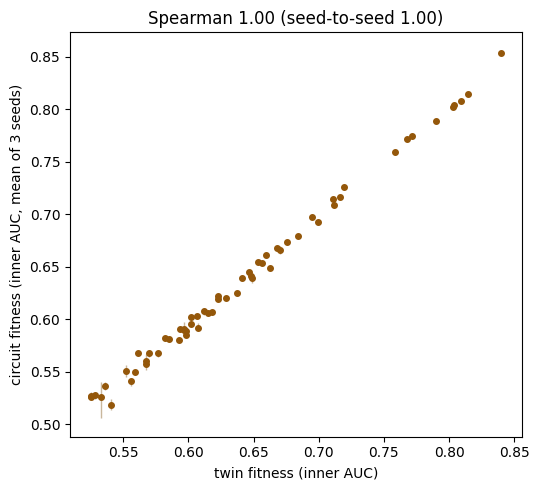

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 5))
lo_err = table["circuit mean"] - table[["circuit seed %d" % s for s in seeds]].min(axis=1)
hi_err = table[["circuit seed %d" % s for s in seeds]].max(axis=1) - table["circuit mean"]
ax.errorbar(table[col], table["circuit mean"], yerr=[lo_err, hi_err], fmt="o", ms=4, color="#94570A",
            ecolor="#C9B79C", elinewidth=1)
ax.set_xlabel("twin fitness (inner AUC)")
ax.set_ylabel("circuit fitness (inner AUC, mean of %d seeds)" % len(seeds))
ax.set_title("Spearman %.2f (seed-to-seed %.2f)" % (summary["twin_spearman"], summary["seed_to_seed_spearman"]))
plt.tight_layout()
plt.savefig(f"{out_dir}/ranking_check.png", dpi=150)
plt.show()

In [12]:
!ls -lh {out_dir}

total 68K
-rw-r--r-- 1 root root 11K Nov 26 13:46 ranking_check.csv
-rw-r--r-- 1 root root 49K Nov 26 13:46 ranking_check.png
-rw-r--r-- 1 root root 322 Nov 26 13:46 summary.json
